In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:


file_path = "machine.csv"

with open(file_path, "r", encoding="latin1") as f:
    lines = f.readlines()

print("Total lines:", len(lines))
print("\nFirst 10 lines:\n")

for i, line in enumerate(lines[:10], start=1):
    print(f"Line {i}: {line.rstrip()}")


Total lines: 4644

First 10 lines:

Line 1: PK     ! ãìY]     [Content_Types].xml ¢(                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  ¬ÏN1ï&¾Ã¦WÃ<cX8øç¨$âÔvmh;MgÀåíÍAcVËö°Óß÷uÒéxÚzW¬!ÅPQ9ÆE%ÞæO[Q«`Ã Ø éäòb<ßD ¢õ.P%æx'%é¼¢#Ö»WL%¦J/Õäõpx#5Àî2Ädü µZ9.[°5IàH÷ÛÂU	£³Z±Å ×Áü¢¾ek¨±®ZïD!{ù×ÝÆ5¤d
Line 2: 3øYy¨lüÀ´|G\Sz<±®­zå!pI12Ô °we^K¯lØÈÕ$ó2:³IwÀ|Lð ó÷tsH¼q@çî|=nTóÊÉÅÙ
Line 3: ~f1¨g	#I	þßÝ¤t»1aÄ¾g¥ïÆí*Æ;Ý0}pÉ'   ÿÿ PK     ! Eñ   

In [ ]:


import pandas as pd

# Read the Excel file instead of CSV
df = pd.read_excel(
    "machine.csv",
    engine="openpyxl"
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()



Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF      

In [ ]:
print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Records:", df.duplicated().sum())
df.describe()

Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate Records: 0


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
print("Machine Failure Distribution:")
print(df["Machine failure"].value_counts())

print("\nFailure Percentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


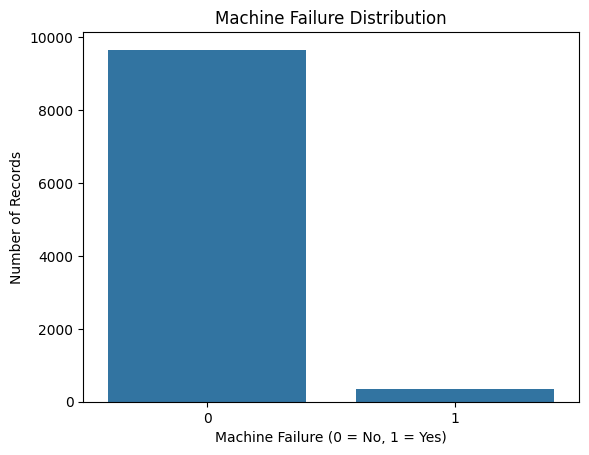

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

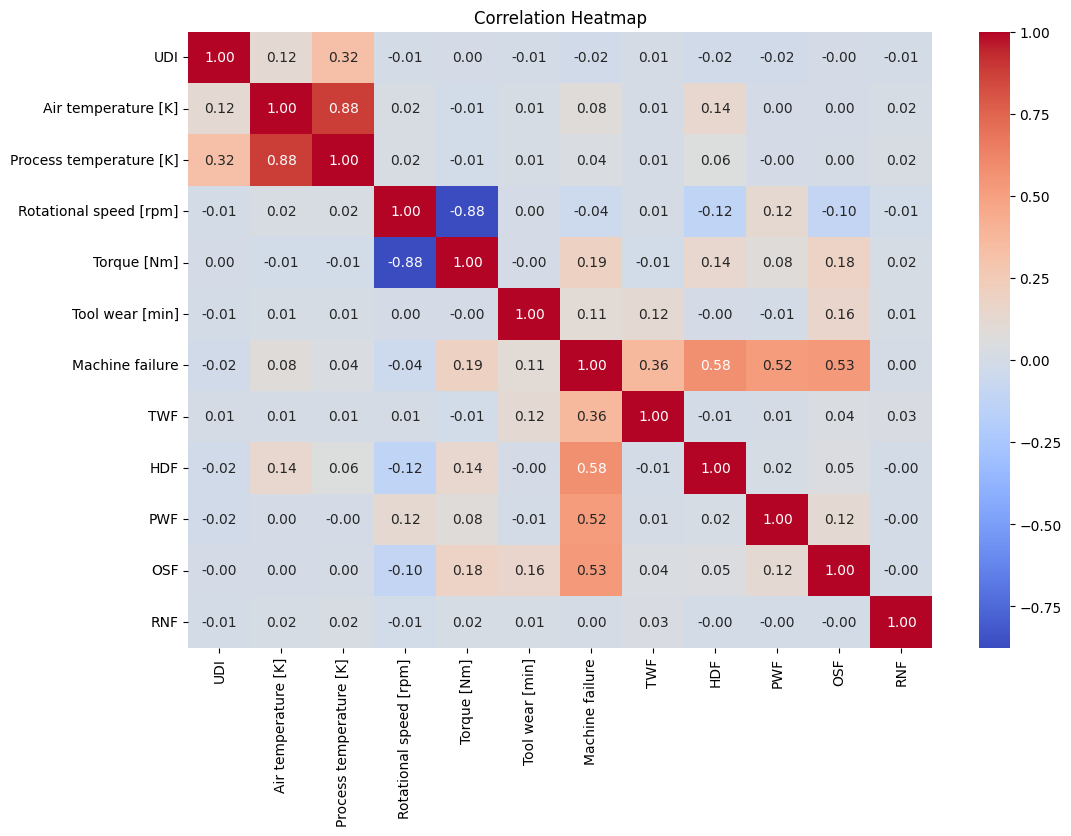

In [ ]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
# Target
y = df["Machine failure"]

# Remove unnecessary and leakage columns
columns_to_remove = [
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

# Input features
X = df.drop(columns=columns_to_remove)

print("Input Features:")
print(X.columns.tolist())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Input Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

X Shape: (10000, 6)
y Shape: (10000,)


Correlation with Machine failure:

Machine failure            1.000000
HDF                        0.575800
OSF                        0.531083
PWF                        0.522812
TWF                        0.362904
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
RNF                        0.004516
UDI                       -0.022892
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64


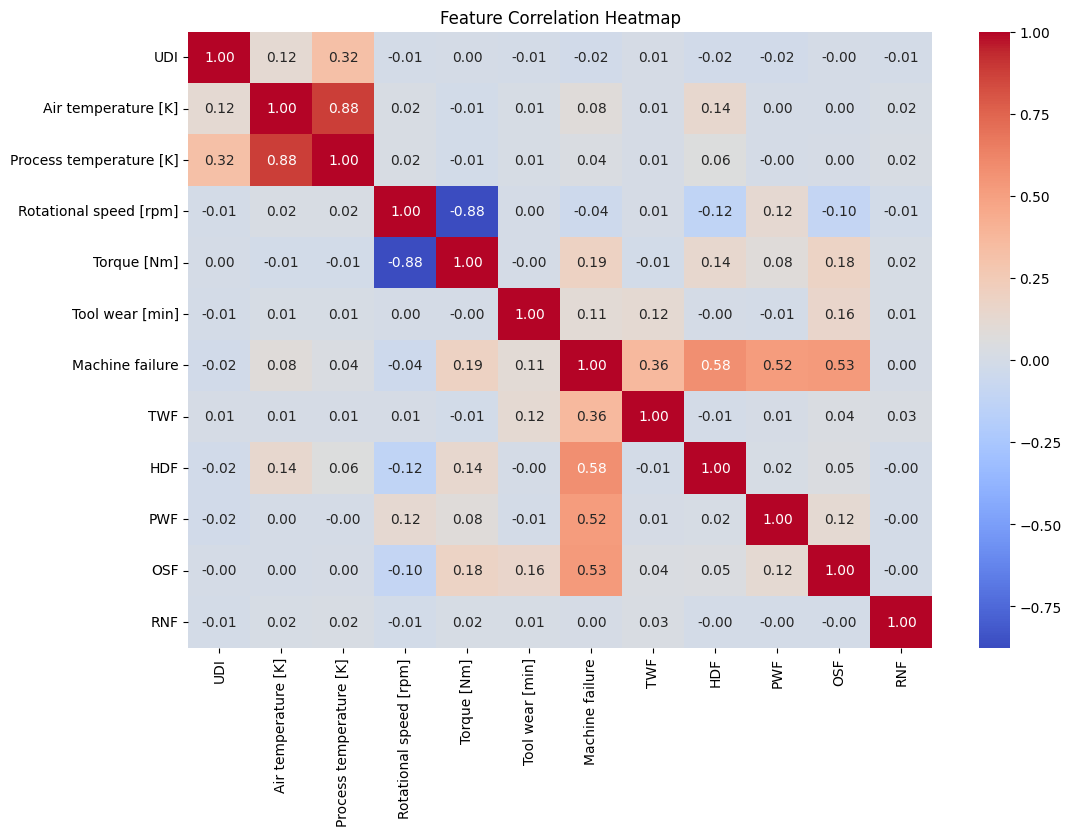

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read the file as an Excel document to bypass the zipped XML format issue
df = pd.read_excel('machine.csv')

# Select only numeric columns for the correlation check
numeric_df = df.select_dtypes(include=['number'])

# Calculate how every numeric column correlates with 'Machine failure'
if 'Machine failure' in numeric_df.columns:
    correlation_with_target = numeric_df.corr()['Machine failure'].sort_values(ascending=False)

    print("Correlation with Machine failure:\n")
    print(correlation_with_target)

    # Plot a heatmap to visualize the correlations
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Feature Correlation Heatmap")
    plt.show()
else:
    print("Columns loaded correctly are:")
    print(df.columns.tolist())

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 6)
Testing Features: (2000, 6)
Training Target: (8000,)
Testing Target: (2000,)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load data and define X and y
df = pd.read_excel('machine.csv')

leakage_cols = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df_clean = df.drop(columns=leakage_cols)

X = df_clean.drop(columns=['Machine failure'])
y = df_clean['Machine failure']

# 2. Build the Preprocessor (This fixes the 'M' string error)
numeric_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
categorical_features = ['Type']

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop='first'), categorical_features)
    ]
)

# 3. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Build the Pipeline using your preprocessor structure
log_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# 5. Train and Evaluate the Base Model
print("Training Base Logistic Regression...")
log_pipeline.fit(X_train, y_train)
y_pred_log = log_pipeline.predict(X_test)

print("\n=== Base Logistic Regression Evaluation ===")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))

# 6. Hyperparameter Tuning using GridSearchCV
print("\nRunning Cross-Validation and Tuning...")
param_grid_log = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['lbfgs', 'liblinear']
}

grid_log = GridSearchCV(log_pipeline, param_grid_log, cv=5, scoring='f1')
grid_log.fit(X_train, y_train)

# 7. Evaluate the Tuned Model
print("\n=== Tuned Logistic Regression Results ===")
print("Best Parameters:", grid_log.best_params_)
print("Best Cross-Validation F1 Score:", grid_log.best_score_)

best_log_model = grid_log.best_estimator_
y_pred_best_log = best_log_model.predict(X_test)

print("\nTuned Model Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_log))
print("\nTuned Model Classification Report:\n", classification_report(y_test, y_pred_best_log))

Training Base Logistic Regression...

=== Base Logistic Regression Evaluation ===
Accuracy: 0.8245

Confusion Matrix:
 [[1593  339]
 [  12   56]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000


Running Cross-Validation and Tuning...

=== Tuned Logistic Regression Results ===
Best Parameters: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Best Cross-Validation F1 Score: 0.23490735052667633

Tuned Model Confusion Matrix:
 [[1593  339]
 [  12   56]]

Tuned Model Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                          

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Build the Pipeline for Decision Tree
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

# 2. Train and Evaluate the Base Model
print("Training Base Decision Tree...")
dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)

print("\n=== Base Decision Tree Evaluation ===")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

# 3. Hyperparameter Tuning using GridSearchCV
print("\nRunning Cross-Validation and Tuning...")
param_grid_dt = {
    'classifier__max_depth': [None, 5, 10, 15],
    'classifier__min_samples_split': [2, 10, 20],
    'classifier__criterion': ['gini', 'entropy']
}

# scoring='f1' prioritizes predicting the actual failures correctly
grid_dt = GridSearchCV(dt_pipeline, param_grid_dt, cv=5, scoring='f1')
grid_dt.fit(X_train, y_train)

# 4. Evaluate the Tuned Model
print("\n=== Tuned Decision Tree Results ===")
print("Best Parameters:", grid_dt.best_params_)
print("Best Cross-Validation F1 Score:", grid_dt.best_score_)

best_dt_model = grid_dt.best_estimator_
y_pred_best_dt = best_dt_model.predict(X_test)

print("\nTuned Model Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_dt))
print("\nTuned Model Classification Report:\n", classification_report(y_test, y_pred_best_dt))

Training Base Decision Tree...

=== Base Decision Tree Evaluation ===
Accuracy: 0.9785

Confusion Matrix:
 [[1915   17]
 [  26   42]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.62      0.66        68

    accuracy                           0.98      2000
   macro avg       0.85      0.80      0.83      2000
weighted avg       0.98      0.98      0.98      2000


Running Cross-Validation and Tuning...

=== Tuned Decision Tree Results ===
Best Parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_split': 2}
Best Cross-Validation F1 Score: 0.6806941231078852

Tuned Model Confusion Matrix:
 [[1916   16]
 [  23   45]]

Tuned Model Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.74      0.66      0.70        68

    a

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Build the Base Pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

# ---------------------------------------------------------
# PART A: BEFORE TUNING (Base Random Forest)
# ---------------------------------------------------------
print("Training Base Random Forest (Before Tuning)...")
rf_pipeline.fit(X_train, y_train)
y_pred_rf_base = rf_pipeline.predict(X_test)

print("\n=== BEFORE TUNING: Base Random Forest Results ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf_base):.4f}")
print("\nBase Model Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf_base))
print("\nBase Model Classification Report:\n", classification_report(y_test, y_pred_rf_base))

# ---------------------------------------------------------
# PART B: AFTER TUNING (Recall-Tuned Random Forest)
# ---------------------------------------------------------
print("\nRunning Cross-Validation and Tuning for Maximum Recall...")
param_grid_rf = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=5, scoring='recall')
grid_rf.fit(X_train, y_train)

best_rf_model = grid_rf.best_estimator_
y_pred_best_rf = best_rf_model.predict(X_test)

print("\n=== AFTER TUNING: Recall-Tuned Random Forest Results ===")
print("Best Parameters:", grid_rf.best_params_)
print(f"Best Cross-Validation Recall Score: {grid_rf.best_score_:.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_best_rf):.4f}")
print("\nTuned Model Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_rf))
print("\nTuned Model Classification Report:\n", classification_report(y_test, y_pred_best_rf))

Training Base Random Forest (Before Tuning)...

=== BEFORE TUNING: Base Random Forest Results ===
Accuracy: 0.9810

Base Model Confusion Matrix:
 [[1930    2]
 [  36   32]]

Base Model Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.94      0.47      0.63        68

    accuracy                           0.98      2000
   macro avg       0.96      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000


Running Cross-Validation and Tuning for Maximum Recall...

=== AFTER TUNING: Recall-Tuned Random Forest Results ===
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Best Cross-Validation Recall Score: 0.8412
Accuracy: 0.9390

Tuned Model Confusion Matrix:
 [[1817  115]
 [   7   61]]

Tuned Model Classification Report:
               precision    recall  f1-score   support

           0       1

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Compare all three tuned models on the untouched test set (X_test, y_test)
tuned_models = {
    "Tuned Logistic Regression": best_log_model,
    "Tuned Decision Tree": best_dt_model,
    "Recall-Tuned Random Forest": best_rf_model
}

comparison_rows = []
for name, model in tuned_models.items():
    preds = model.predict(X_test)
    comparison_rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision (Failure)": round(precision_score(y_test, preds), 4),
        "Recall (Failure)": round(recall_score(y_test, preds), 4),
        "F1-Score (Failure)": round(f1_score(y_test, preds), 4)
    })

comparison_df = pd.DataFrame(comparison_rows)
print("=== Final Tuned Model Comparison Table ===")
print(comparison_df.to_string(index=False))

# Select the best model (Recall-Tuned Random Forest)
selected_model = best_rf_model
y_pred_final = selected_model.predict(X_test)

print("\n=== Selected Best Model: Recall-Tuned Random Forest ===")
print("Final Test Confusion Matrix:\n", confusion_matrix(y_test, y_pred_final))
print("\nFinal Test Classification Report:\n", classification_report(y_test, y_pred_final))

=== Final Tuned Model Comparison Table ===
                     Model  Accuracy  Precision (Failure)  Recall (Failure)  F1-Score (Failure)
 Tuned Logistic Regression    0.8245               0.1418            0.8235              0.2419
       Tuned Decision Tree    0.9805               0.7377            0.6618              0.6977
Recall-Tuned Random Forest    0.9390               0.3466            0.8971              0.5000

=== Selected Best Model: Recall-Tuned Random Forest ===
Final Test Confusion Matrix:
 [[1817  115]
 [   7   61]]

Final Test Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.94      0.97      1932
           1       0.35      0.90      0.50        68

    accuracy                           0.94      2000
   macro avg       0.67      0.92      0.73      2000
weighted avg       0.97      0.94      0.95      2000



In [ ]:
import joblib

model_filename = "best_machine_failure_model.pkl"
joblib.dump(selected_model, model_filename)

print(f"Success! Saved complete pipeline and model as '{model_filename}'")

Success! Saved complete pipeline and model as 'best_machine_failure_model.pkl'


In [ ]:
import pandas as pd
import joblib

# Load the saved pipeline from disk
loaded_model = joblib.load("best_machine_failure_model.pkl")

def predict_machine_failure():
    print("=" * 50)
    print("Industrial Machine Failure Prediction System")
    print("=" * 50)

    try:
        machine_type = input("Enter Machine Type (L, M, H): ").strip().upper()
        if machine_type not in ["L", "M", "H"]:
            print("Invalid Machine Type! Please enter L, M, or H.")
            return

        air_temp = float(input("Enter Air temperature [K] (e.g., 300.0): "))
        process_temp = float(input("Enter Process temperature [K] (e.g., 310.0): "))
        rot_speed = float(input("Enter Rotational speed [rpm] (e.g., 1500): "))
        torque = float(input("Enter Torque [Nm] (e.g., 40.0): "))
        tool_wear = float(input("Enter Tool wear [min] (e.g., 50): "))

        # Column names must match X_train exactly
        new_data = pd.DataFrame({
            "Type": [machine_type],
            "Air temperature [K]": [air_temp],
            "Process temperature [K]": [process_temp],
            "Rotational speed [rpm]": [rot_speed],
            "Torque [Nm]": [torque],
            "Tool wear [min]": [tool_wear]
        })

        prediction = loaded_model.predict(new_data)[0]
        failure_prob = loaded_model.predict_proba(new_data)[0][1] * 100

        print("\n--- Prediction Result ---")
        if prediction == 1:
            print("Machine Failure: Yes")
            print(f"Estimated Failure Probability: {failure_prob:.2f}%")
            print("Status: Maintenance required immediately.")
        else:
            print("Machine Failure: No")
            print(f"Estimated Failure Probability: {failure_prob:.2f}%")
            print("Status: Machine operating normally.")

    except ValueError:
        print("\nInvalid input! Please enter numeric values for the sensor readings.")

# Run the demonstration
predict_machine_failure()

Industrial Machine Failure Prediction System
Enter Machine Type (L, M, H): L
Enter Air temperature [K] (e.g., 300.0): 298.5
Enter Process temperature [K] (e.g., 310.0): 308.8
Enter Rotational speed [rpm] (e.g., 1500): 1550
Enter Torque [Nm] (e.g., 40.0): 40.0
Enter Tool wear [min] (e.g., 50): 20

--- Prediction Result ---
Machine Failure: No
Estimated Failure Probability: 6.84%
Status: Machine operating normally.
